In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

import tensorflow as tf
from tensorflow import keras

In [20]:


np.random.seed(42)

n = 500

data = {
    "Study_Hours": np.random.uniform(1, 10, n),
    "Sleep_Hours": np.random.uniform(5, 9, n),
    "Attendance": np.random.uniform(60, 100, n),
    "Previous_Score": np.random.uniform(40, 95, n)
}

df = pd.DataFrame(data)

# Create Marks using the features + some random variation
df["Marks"] = (
    4 * df["Study_Hours"]
    + 2 * df["Sleep_Hours"]
    + 0.3 * df["Attendance"]
    + 0.4 * df["Previous_Score"]
    + np.random.normal(0, 5, n)
)

# Keep marks between 0 and 100
df["Marks"] = df["Marks"].clip(0, 100)

print(df.head())
print(df.shape)

   Study_Hours  Sleep_Hours  Attendance  Previous_Score      Marks
0     4.370861     7.792647   67.405317       68.549498  76.320219
1     9.556429     7.144385   81.676038       66.355003  99.424897
2     7.587945     6.238110   94.917833       41.410314  86.735084
3     6.387926     8.255180   89.288995       58.768631  94.193044
4     2.404168     7.738925   92.262446       60.910759  81.705481
(500, 5)


In [21]:
X = df[["Study_Hours"]]
y = df["Marks"]

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [23]:
# Build neural network 
model = keras.Sequential([
    keras.layers.Dense(10, activation="relu"),
    keras.layers.Dense(1)
])

In [24]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [25]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=2
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 6987.8052 - mae: 82.8445
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 5899.0923 - mae: 76.2072
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 4508.5542 - mae: 66.6372
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3090.5793 - mae: 54.7737
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1927.6266 - mae: 42.1881
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1175.3617 - mae: 30.4680
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 808.3434 - mae: 23.1549
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 672.5714 - mae: 21.2284
Epoch 9/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 631.1319 - mae: 20.8109
Epoch 10/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 614.8226 - mae: 20.6649
Epoch 11/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 603.0199 - mae: 20.4808
Epoch 12/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - l

In [26]:
y_pred = model.predict(X_test)

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step


In [27]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred.flatten())

print("MAE:", mae)

MAE: 6.423726745720061


In [28]:
print("Actual:", y_test.values)
print("Predicted:", y_pred.flatten())

Actual: [ 94.25241561 100.          57.20285145  96.87971365  95.94600332
  83.75501751  81.26265877  78.95706513  76.46381582  84.73463087
  98.26084179  74.63441692 100.          92.55502323  58.88715092
 100.          83.87840221  78.58857464  74.81429437  96.61141655
  87.87034149  84.61912084  98.62071152  70.69652429  82.41356654
  88.32997554  59.74795428  76.42984407  90.11707198  79.15147298
 100.          88.95876733  72.11823133  86.62785138  86.73508385
  83.40413368  69.44642248 100.          89.22166712  87.98394909
  93.53300051  81.55552728  88.0315725  100.          97.51339167
  84.62131724  76.32021948 100.          94.00151355  87.43712591
  77.45396802 100.          78.37641464  76.0166499   84.59398928
 100.          85.33135413  91.7620232   85.18417877  83.24047611
  91.35360409  59.57044471  87.91389992  95.68591244  73.43233526
  65.60909117  84.15066858  80.76137781  85.08324643  77.69868265
  97.06922971  84.86240061  98.73819002  55.64799302  81.07852923
 1

In [29]:
print(history.history["loss"])

[6987.80517578125, 5899.09228515625, 4508.55419921875, 3090.579345703125, 1927.6265869140625, 1175.3616943359375, 808.3433837890625, 672.5713500976562, 631.1318969726562, 614.8225708007812, 603.0198974609375, 590.699951171875, 578.9209594726562, 566.18115234375, 553.5042724609375, 540.0519409179688, 527.1408081054688, 513.9334106445312, 500.1488952636719, 487.2196960449219, 473.8485107421875, 459.8267822265625, 446.43499755859375, 432.9669494628906, 419.2788391113281, 406.0502014160156, 393.0343017578125, 379.5055847167969, 365.9498291015625, 352.6883850097656, 340.0773010253906, 326.7685852050781, 313.59136962890625, 300.9662170410156, 288.2629699707031, 275.5248107910156, 263.103515625, 250.8245086669922, 239.35108947753906, 228.03836059570312, 216.20933532714844, 205.38925170898438, 194.09185791015625, 183.99951171875, 173.72518920898438, 163.93923950195312, 154.5355987548828, 145.4935760498047, 136.9293212890625, 128.88314819335938, 121.22377014160156, 114.24530029296875, 107.20597

In [30]:
import matplotlib.pyplot as plt

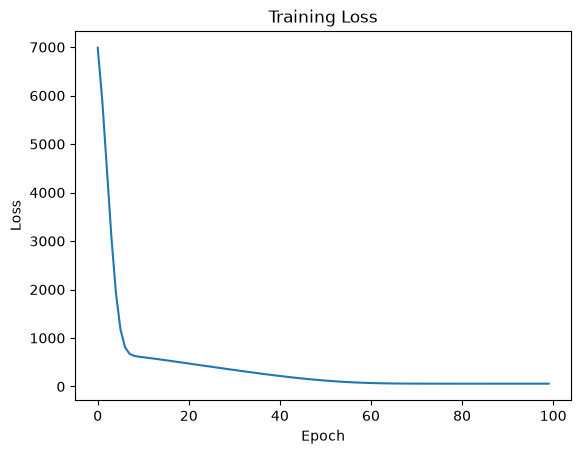

In [31]:
plt.plot(history.history["loss"])
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

In [ ]:
# TensorFlow
# - What TensorFlow is
# - It is the framework/engine used for building and training neural networks
# - TensorFlow handles the calculations, gradients, and parameter updates during training
# Keras
# - What Keras is
# - It is the high-level API used to build neural networks more easily
# Keras concepts we've used:
# from tensorflow import keras


# - keras.Sequential() → puts layers one after another
# - keras.layers.Dense() → creates fully connected layers
# - activation="relu" → applies ReLU
# - model.compile() → configures how the model learns
# - model.fit() → trains the model
# - model.predict() → makes predictions
# - model.summary() → shows model structure
# We also actually built and trained a TensorFlow/Keras neural network, so this isn't just theory.
# One distinction
# We have learned the basic TensorFlow/Keras workflow, but we haven't finished TensorFlow/Keras completely.
# We'll continue learning it as we build:
# binary classification → multiclass classification → overfitting → dropout → early stopping → CNN, etc.
# So in the roadmap, TensorFlow + Keras = started/covered at the basic level ✅, not "completely finished."